# Exploratory Data Analysis — Heart Disease UCI Dataset

Run this notebook after `python scripts/download_data.py`. All plots are saved
to `artifacts/eda/` so the report can reference them without re-running.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent
OUT = ROOT / "artifacts" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / "data" / "heart_disease_clean.csv")
print(f"Rows: {len(df)}, Columns: {df.shape[1]}")
df.head()

Rows: 297, Columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


/var/folders/l9/k4f7gjyx3z5_bq_fss708c7w0000gp/T/ipykernel_33470/134928400.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No disease (0)", "Disease (1)"])


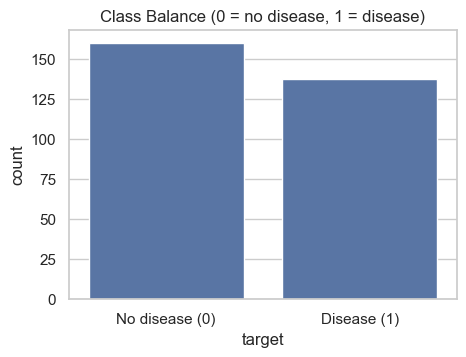

target
0    0.538721
1    0.461279
Name: proportion, dtype: float64

In [2]:
# Class balance
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="target", data=df, ax=ax)
ax.set_title("Class Balance (0 = no disease, 1 = disease)")
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
fig.savefig(OUT / "class_balance.png", bbox_inches="tight", dpi=150)
plt.show()
df["target"].value_counts(normalize=True)

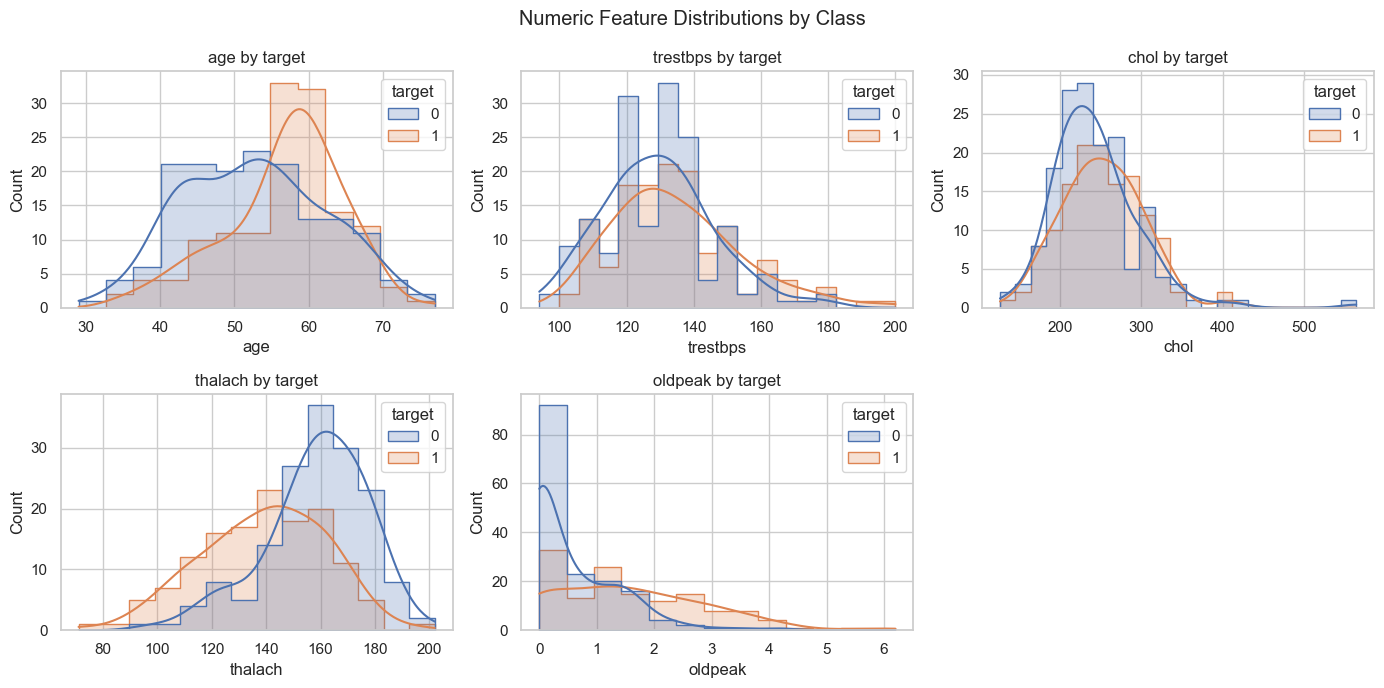

In [3]:
# Distributions of numeric features, split by target
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, numeric):
    sns.histplot(df, x=col, hue="target", kde=True, ax=ax, element="step")
    ax.set_title(f"{col} by target")
axes.flat[-1].axis("off")
fig.suptitle("Numeric Feature Distributions by Class")
fig.tight_layout()
fig.savefig(OUT / "numeric_distributions.png", bbox_inches="tight", dpi=150)
plt.show()

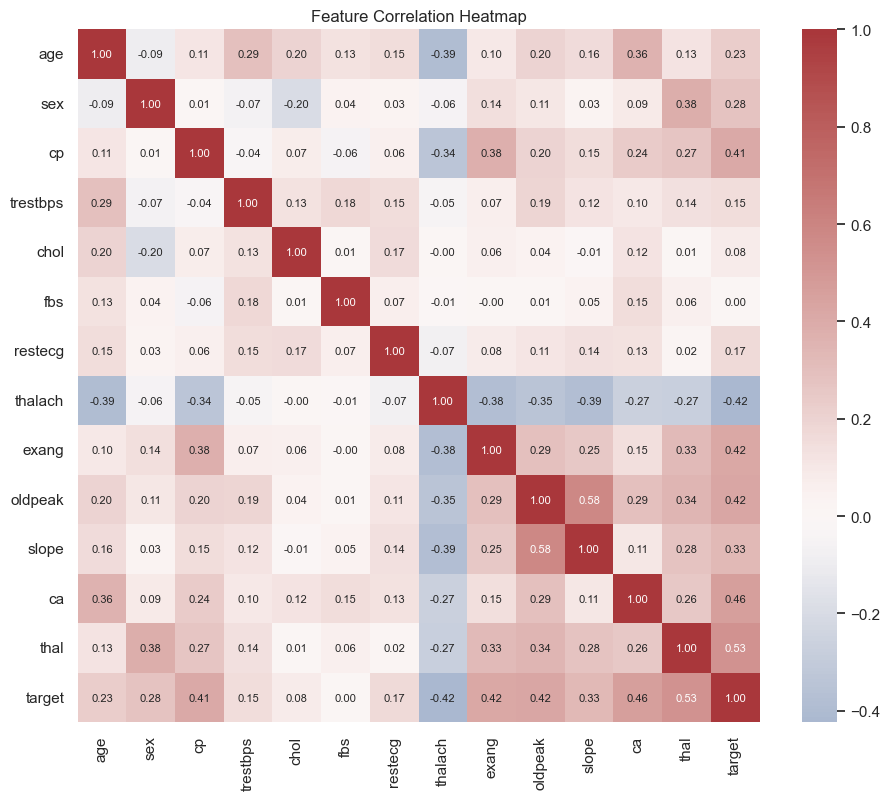

thal       0.526640
ca         0.463189
oldpeak    0.424052
thalach   -0.423817
exang      0.421355
cp         0.408945
slope      0.333049
sex        0.278467
Name: target, dtype: float64

In [4]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(11, 9))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Feature Correlation Heatmap")
fig.savefig(OUT / "correlation_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()
corr["target"].drop("target").sort_values(key=abs, ascending=False).head(8)

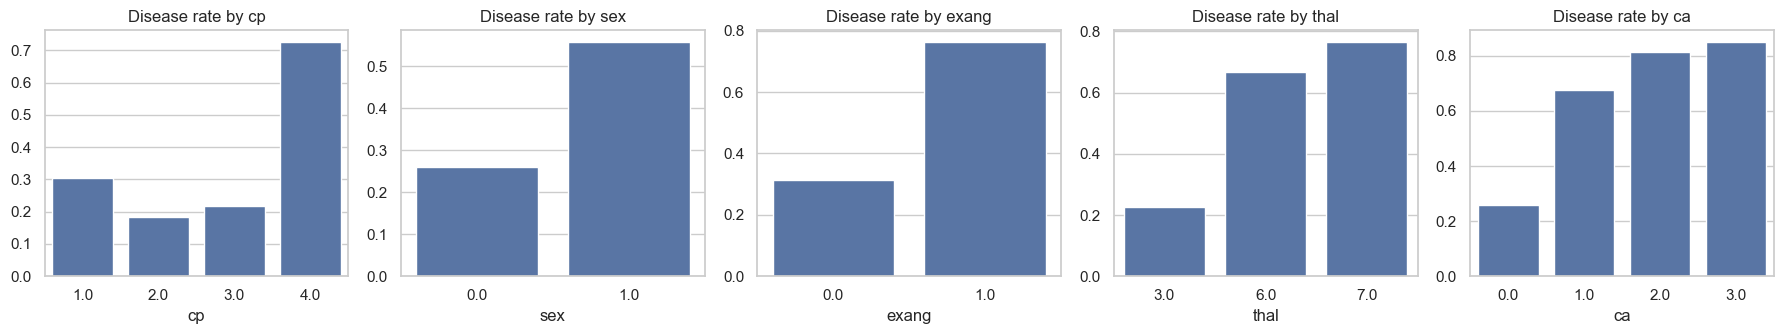

In [5]:
# Categorical features vs target
cats = ["cp", "sex", "exang", "thal", "ca"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, cats):
    sns.barplot(x=col, y="target", data=df, ax=ax, errorbar=None)
    ax.set_title(f"Disease rate by {col}")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(OUT / "categorical_rates.png", bbox_inches="tight", dpi=150)
plt.show()